In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("DataCo_Cleaned_Interim.csv")

df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"], errors="coerce"
)

print("Total Records:", len(df))

Total Records: 13629


In [3]:
df = df.drop_duplicates("Order Id").copy()

df["Cancelled"] = (
    (df["Order Status"] == "CANCELED") |
    (df["Delivery Status"] == "Shipping canceled")
)

df["Eligible"] = (
    ~df["Cancelled"] &
    df["order date (DateOrders)"].notna() &
    df["shipping date (DateOrders)"].notna()
)

df["On Time"] = df["Delivery Status"].isin(
    ["Shipping on time", "Advance shipping"]
)

df["Delayed"] = df["Delivery Status"] == "Late delivery"

df = df[df["Eligible"]].copy()

df["Month"] = df["order date (DateOrders)"].dt.to_period("M").astype(str)

In [4]:
monthly = df.groupby(["Order Region", "Month"]).agg(
    Eligible_Orders=("Order Id", "count"),
    On_Time_Orders=("On Time", "sum"),
    Delayed_Orders=("Delayed", "sum")
).reset_index()

monthly["On-Time Rate (%)"] = (
    monthly["On_Time_Orders"] / monthly["Eligible_Orders"] * 100
)

monthly["Delay Rate (%)"] = (
    monthly["Delayed_Orders"] / monthly["Eligible_Orders"] * 100
)

monthly = monthly.round(2)

monthly.head()

,Order Region,Month,Eligible_Orders,On_Time_Orders,Delayed_Orders,On-Time Rate (%),Delay Rate (%)
0,Canada,2016-08,3,3,0,100.00,0.00
1,Canada,2016-09,8,2,6,25.00,75.00
2,Canada,2016-10,9,4,5,44.44,55.56
3,Canada,2016-11,5,4,1,80.00,20.00
4,Canada,2016-12,12,9,3,75.00,25.00


In [5]:
on_time_comparison = monthly[[
    "Order Region", "Month", "Eligible_Orders",
    "On_Time_Orders", "On-Time Rate (%)"
]].copy()

on_time_comparison.head()

,Order Region,Month,Eligible_Orders,On_Time_Orders,On-Time Rate (%)
0,Canada,2016-08,3,3,100.00
1,Canada,2016-09,8,2,25.00
2,Canada,2016-10,9,4,44.44
3,Canada,2016-11,5,4,80.00
4,Canada,2016-12,12,9,75.00


In [6]:
monthly = monthly.sort_values(["Order Region", "Month"])

monthly["Previous Delay Rate (%)"] = (
    monthly.groupby("Order Region")["Delay Rate (%)"].shift(1)
)

monthly["Trend"] = np.where(
    monthly["Previous Delay Rate (%)"].isna(), "Not Available",
    np.where(
        monthly["Delay Rate (%)"] < monthly["Previous Delay Rate (%)"],
        "Improving",
        np.where(
            monthly["Delay Rate (%)"] > monthly["Previous Delay Rate (%)"],
            "Worsening",
            "Stable"
        )
    )
)

monthly.head()

,Order Region,Month,Eligible_Orders,On_Time_Orders,Delayed_Orders,On-Time Rate (%),Delay Rate (%),Previous Delay Rate (%),Trend
0,Canada,2016-08,3,3,0,100.00,0.00,NaN,Not Available
1,Canada,2016-09,8,2,6,25.00,75.00,0.00,Worsening
2,Canada,2016-10,9,4,5,44.44,55.56,75.00,Improving
3,Canada,2016-11,5,4,1,80.00,20.00,55.56,Improving
4,Canada,2016-12,12,9,3,75.00,25.00,20.00,Worsening


In [7]:
summary = monthly.groupby("Order Region").agg(
    Total_Eligible_Orders=("Eligible_Orders", "sum"),
    Average_On_Time_Rate=("On-Time Rate (%)", "mean"),
    Average_Delay_Rate=("Delay Rate (%)", "mean")
).reset_index()

summary = summary.round(2)

summary.head()

,Order Region,Total_Eligible_Orders,Average_On_Time_Rate,Average_Delay_Rate
0,Canada,43,62.41,37.59
1,Caribbean,315,50.56,49.44
2,Central Africa,81,53.72,46.28
3,Central America,1064,47.58,52.42
4,Central Asia,31,33.33,66.67


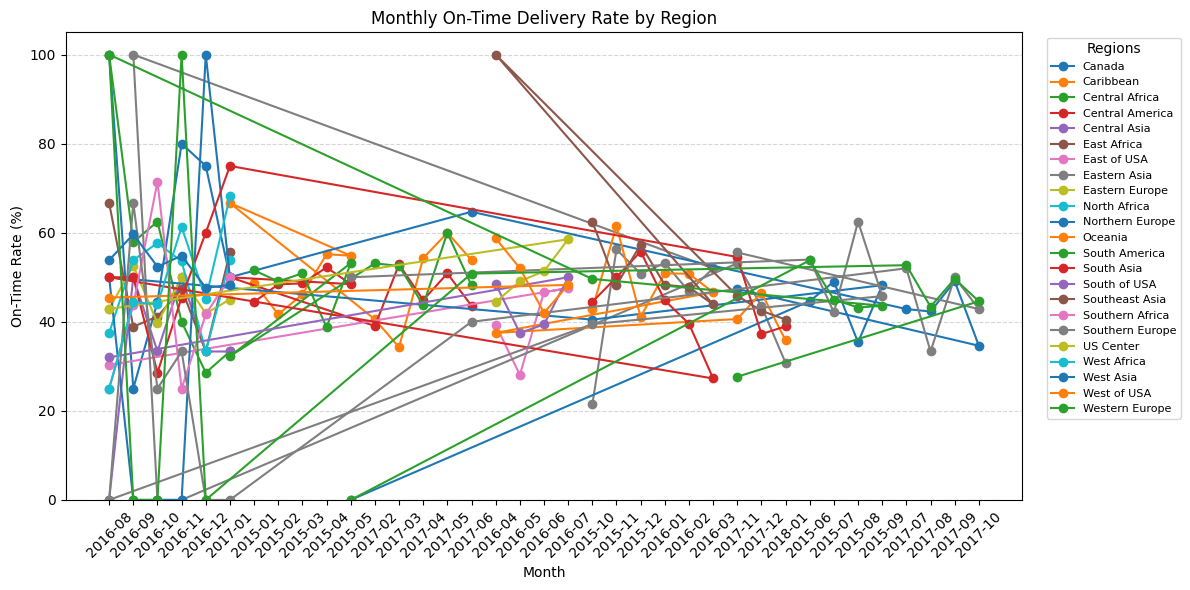

In [12]:
plt.figure(figsize=(12, 6))

for region, data in monthly.groupby("Order Region"):
    plt.plot(
        data["Month"],
        data["On-Time Rate (%)"],
        marker="o",
        linewidth=1.5,
        label=region
    )

plt.title("Monthly On-Time Delivery Rate by Region")
plt.xlabel("Month")
plt.ylabel("On-Time Rate (%)")
plt.xticks(rotation=45)
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(
    title="Regions",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)
plt.tight_layout()
plt.show()

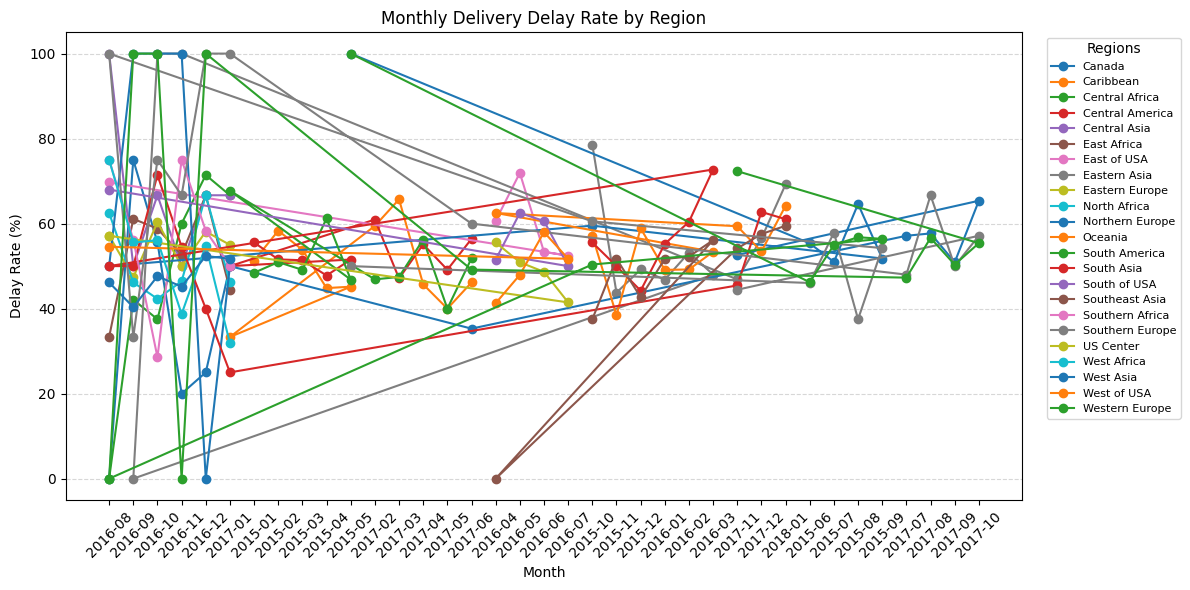

In [11]:
plt.figure(figsize=(12, 6))

for region, data in monthly.groupby("Order Region"):
    plt.plot(
        data["Month"],
        data["Delay Rate (%)"],
        marker="o",
        linewidth=1.5,
        label=region
    )

plt.title("Monthly Delivery Delay Rate by Region")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(
    title="Regions",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)
plt.tight_layout()
plt.show()

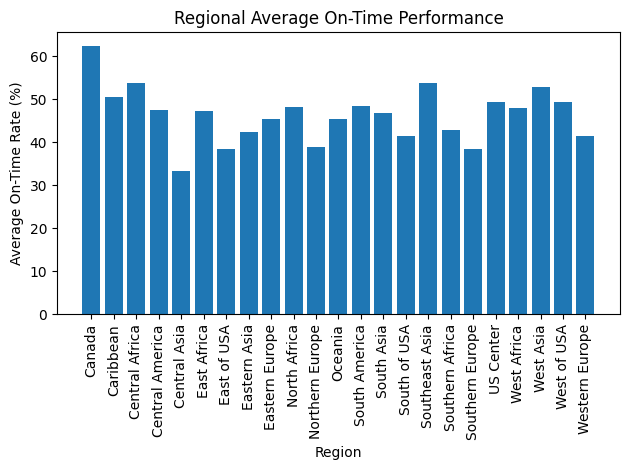

In [10]:
plt.bar(summary["Order Region"], summary["Average_On_Time_Rate"])

plt.title("Regional Average On-Time Performance")
plt.xlabel("Region")
plt.ylabel("Average On-Time Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()